# Test Notebook for 2D Empathic Grid Environment

This notebook contains various tests and visualizations for the 2D grid environment.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from collections import deque
from env_2d import EmpathicGridEnv
from agent_2d import Agent, DQNAgent

# Set random seed for reproducibility
np.random.seed(42)


## Test 1: Single Agent Environment Setup

Test basic environment initialization with a single agent.


In [2]:
# Create environment with single agent
env = EmpathicGridEnv(
    grid_size=10,
    num_agents=1,
    num_resources=5,
    vision_radius=2,
    render_mode=None
)

# Create single agent
agent = Agent(agent_id=0, memory_size=10)
env.agents = [agent]

# Reset environment
obs, info = env.reset(seed=42)

print(f"Grid size: {env.grid_size}x{env.grid_size}")
print(f"Agent position: {env.agent_positions[0]}")
print(f"Number of resources: {len(env.resource_positions)}")
print(f"Resource positions: {env.resource_positions}")
print(f"Observation shape: {obs[0].shape}")
print(f"Vision size: {env.vision_size}x{env.vision_size}")


Grid size: 10x10
Agent position: (np.int64(0), np.int64(7))
Number of resources: 5
Resource positions: [(np.int64(6), np.int64(4)), (np.int64(4), np.int64(8)), (np.int64(0), np.int64(6)), (np.int64(2), np.int64(0)), (np.int64(5), np.int64(9))]
Observation shape: (5, 5, 3)
Vision size: 5x5


## Test 2: Visualize Agent's Observation Window

Display what the agent sees in its local vision area.


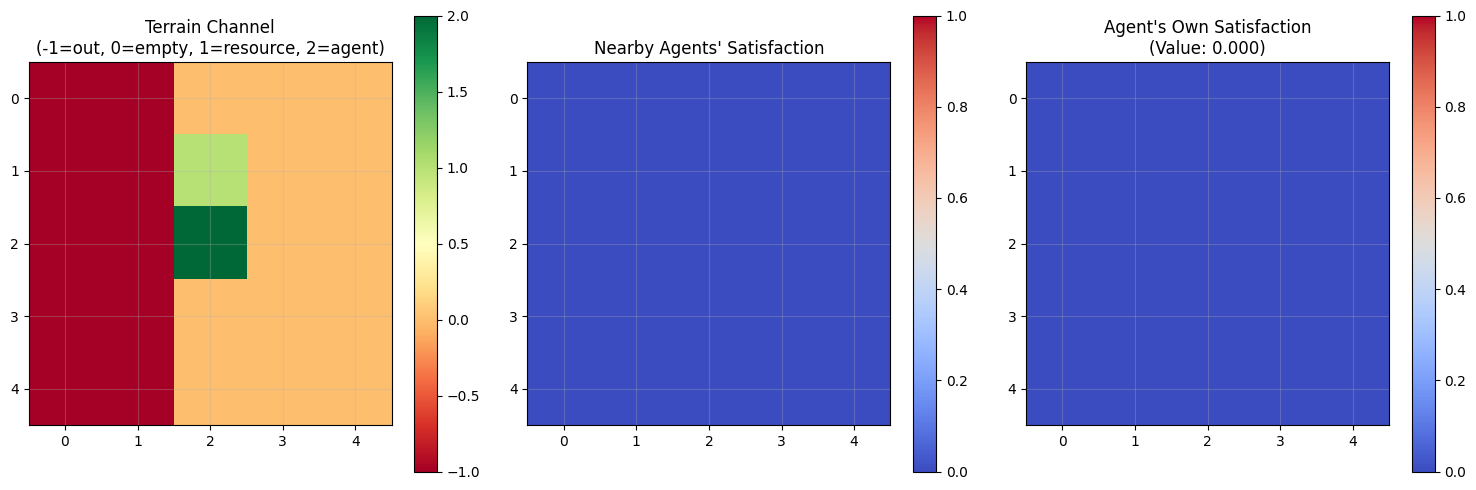


Center cell (agent position):
  Terrain value: 2.0
  Nearby satisfaction: 0.000
  Own satisfaction: 0.000


In [3]:
def visualize_observation(env, agent_idx, obs):
    """Visualize the agent's observation window."""
    fig, axes = plt.subplots(1, 3, figsize=(15, 5))
    
    # Channel 0: Terrain
    terrain = obs[:, :, 0]
    im1 = axes[0].imshow(terrain, cmap='RdYlGn', vmin=-1, vmax=2)
    axes[0].set_title('Terrain Channel\n(-1=out, 0=empty, 1=resource, 2=agent)')
    axes[0].grid(True, alpha=0.3)
    plt.colorbar(im1, ax=axes[0])
    
    # Channel 1: Other agents' satisfaction
    satisfaction = obs[:, :, 1]
    im2 = axes[1].imshow(satisfaction, cmap='coolwarm', vmin=0, vmax=1)
    axes[1].set_title("Nearby Agents' Satisfaction")
    axes[1].grid(True, alpha=0.3)
    plt.colorbar(im2, ax=axes[1])
    
    # Channel 2: Own satisfaction
    own_satisfaction = obs[:, :, 2]
    im3 = axes[2].imshow(own_satisfaction, cmap='coolwarm', vmin=0, vmax=1)
    axes[2].set_title(f"Agent's Own Satisfaction\n(Value: {own_satisfaction[0,0]:.3f})")
    axes[2].grid(True, alpha=0.3)
    plt.colorbar(im3, ax=axes[2])
    
    plt.tight_layout()
    plt.show()
    
    # Print center cell info (agent's position)
    center = env.vision_radius
    print(f"\nCenter cell (agent position):")
    print(f"  Terrain value: {terrain[center, center]:.1f}")
    print(f"  Nearby satisfaction: {satisfaction[center, center]:.3f}")
    print(f"  Own satisfaction: {own_satisfaction[center, center]:.3f}")

# Get observation for agent 0 (use the obs from reset)
visualize_observation(env, 0, obs[0])


## Test 3: Visualize Full Grid with Agent and Resources

Show the complete grid world with agent and resource positions.


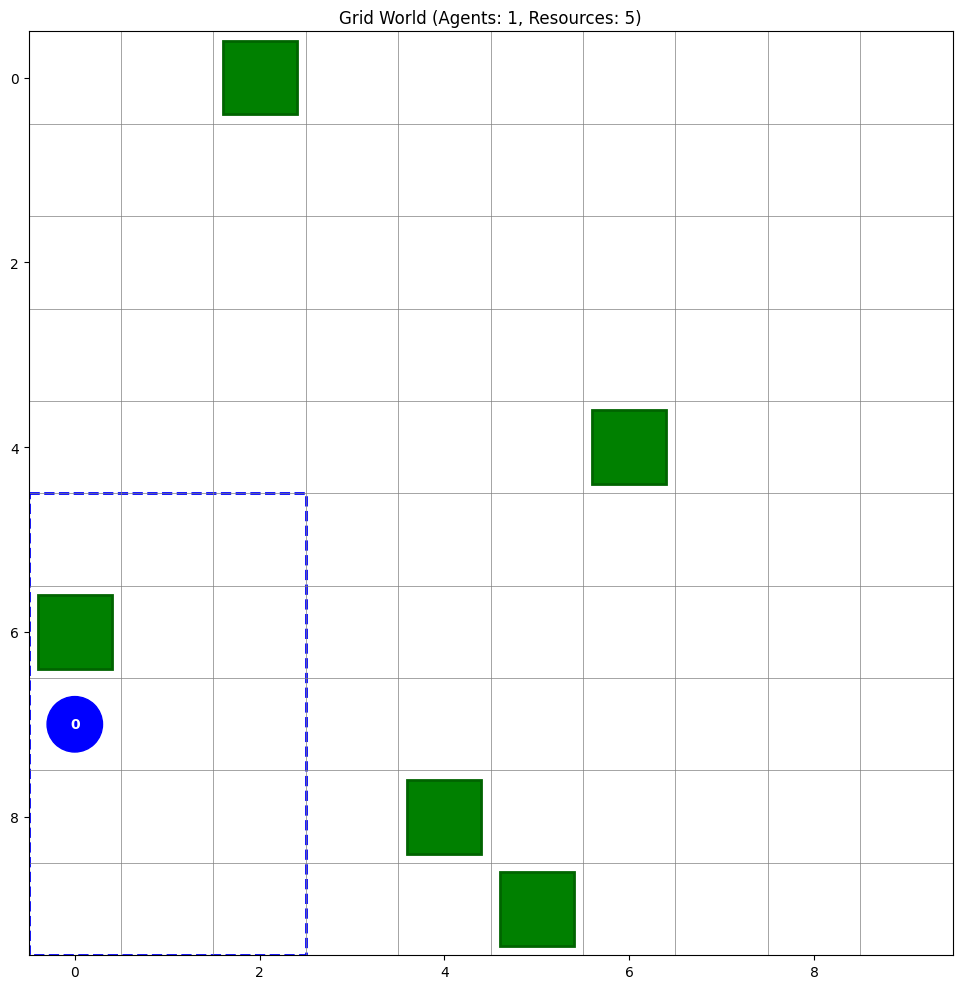

In [4]:
def visualize_grid(env, highlight_agent_idx=None):
    """Visualize the full grid with agents and resources."""
    fig, ax = plt.subplots(figsize=(10, 10))
    
    # Draw grid
    for i in range(env.grid_size + 1):
        ax.axhline(i - 0.5, color='gray', linewidth=0.5)
        ax.axvline(i - 0.5, color='gray', linewidth=0.5)
    
    # Draw resources (green squares)
    for rx, ry in env.resource_positions:
        rect = patches.Rectangle((rx - 0.4, ry - 0.4), 0.8, 0.8,
                                facecolor='green', edgecolor='darkgreen',
                                linewidth=2, zorder=2)
        ax.add_patch(rect)
    
    # Draw agents (colored circles)
    colors = ['blue', 'red', 'orange', 'purple', 'brown', 'pink']
    for idx, (ax_pos, ay_pos) in enumerate(env.agent_positions):
        color = colors[idx % len(colors)]
        circle = patches.Circle((ax_pos, ay_pos), 0.3, color=color, zorder=3)
        ax.add_patch(circle)
        ax.text(ax_pos, ay_pos, str(idx), ha='center', va='center', 
                color='white', fontweight='bold', fontsize=10)
        
        # Highlight vision area for specified agent
        if highlight_agent_idx is not None and idx == highlight_agent_idx:
            vx_min = max(0, ax_pos - env.vision_radius) - 0.5
            vx_max = min(env.grid_size, ax_pos + env.vision_radius + 1) - 0.5
            vy_min = max(0, ay_pos - env.vision_radius) - 0.5
            vy_max = min(env.grid_size, ay_pos + env.vision_radius + 1) - 0.5
            vision_rect = patches.Rectangle((vx_min, vy_min), 
                                          vx_max - vx_min, vy_max - vy_min,
                                          linewidth=2, edgecolor=color, 
                                          facecolor='none', linestyle='--', zorder=1)
            ax.add_patch(vision_rect)
    
    ax.set_xlim(-0.5, env.grid_size - 0.5)
    ax.set_ylim(-0.5, env.grid_size - 0.5)
    ax.set_aspect('equal')
    ax.set_title(f'Grid World (Agents: {len(env.agent_positions)}, Resources: {len(env.resource_positions)})')
    ax.invert_yaxis()  # Match typical grid coordinate system
    plt.tight_layout()
    plt.show()

# Visualize grid
visualize_grid(env, highlight_agent_idx=0)


## Test 4: Single Agent Step-by-Step Movement

Test agent movement and resource consumption step by step.


In [5]:
# Reset environment
obs, _ = env.reset(seed=42)
agent.reset()

print("Initial state:")
print(f"Agent position: {env.agent_positions[0]}")
print(f"Resources: {len(env.resource_positions)}")
print(f"Agent satisfaction: {agent.get_satisfaction():.3f}")
print(f"Agent emotion: {agent.get_emotion():.3f}")
print()

# Perform a few steps
for step in range(5):
    # Simple movement policy: try to move toward nearest resource
    ax, ay = env.agent_positions[0]
    action = np.random.randint(0, 4)  # Random action for testing
    
    actions = [action]
    next_obs, rewards, done, truncated, info = env.step(actions)
    
    new_ax, new_ay = env.agent_positions[0]
    action_names = ['Up', 'Down', 'Left', 'Right']
    
    print(f"Step {step + 1}: {action_names[action]}")
    print(f"  Position: ({ax}, {ay}) -> ({new_ax}, {new_ay})")
    print(f"  Reward: {rewards[0]:.3f}")
    print(f"  Resources remaining: {len(env.resource_positions)}")
    print(f"  Satisfaction: {agent.get_satisfaction():.3f}, Emotion: {agent.get_emotion():.3f}")
    print(f"  Meal history: {list(agent.meal_history)[-5:]}")
    print()
    
    obs = next_obs
    if done:
        print("Episode done!")
        break


Initial state:
Agent position: (np.int64(0), np.int64(7))
Resources: 5
Agent satisfaction: 0.000
Agent emotion: -1.000

Step 1: Left
  Position: (0, 7) -> (0, 7)
  Reward: -0.010
  Resources remaining: 5
  Satisfaction: 0.000, Emotion: -1.000
  Meal history: [0, 0, 0, 0, 0]

Step 2: Right
  Position: (0, 7) -> (1, 7)
  Reward: -0.010
  Resources remaining: 5
  Satisfaction: 0.000, Emotion: -1.000
  Meal history: [0, 0, 0, 0, 0]

Step 3: Up
  Position: (1, 7) -> (1, 6)
  Reward: -0.010
  Resources remaining: 5
  Satisfaction: 0.000, Emotion: -1.000
  Meal history: [0, 0, 0, 0, 0]

Step 4: Left
  Position: (1, 6) -> (0, 6)
  Reward: 0.990
  Resources remaining: 5
  Satisfaction: 0.550, Emotion: -0.800
  Meal history: [0, 0, 0, 0, 1]

Step 5: Left
  Position: (0, 6) -> (0, 6)
  Reward: -0.010
  Resources remaining: 5
  Satisfaction: 0.050, Emotion: -0.800
  Meal history: [0, 0, 0, 1, 0]



## Test 5: Multi-Agent Environment with Empathic Behavior

Test with multiple agents to observe empathic penalty behavior.


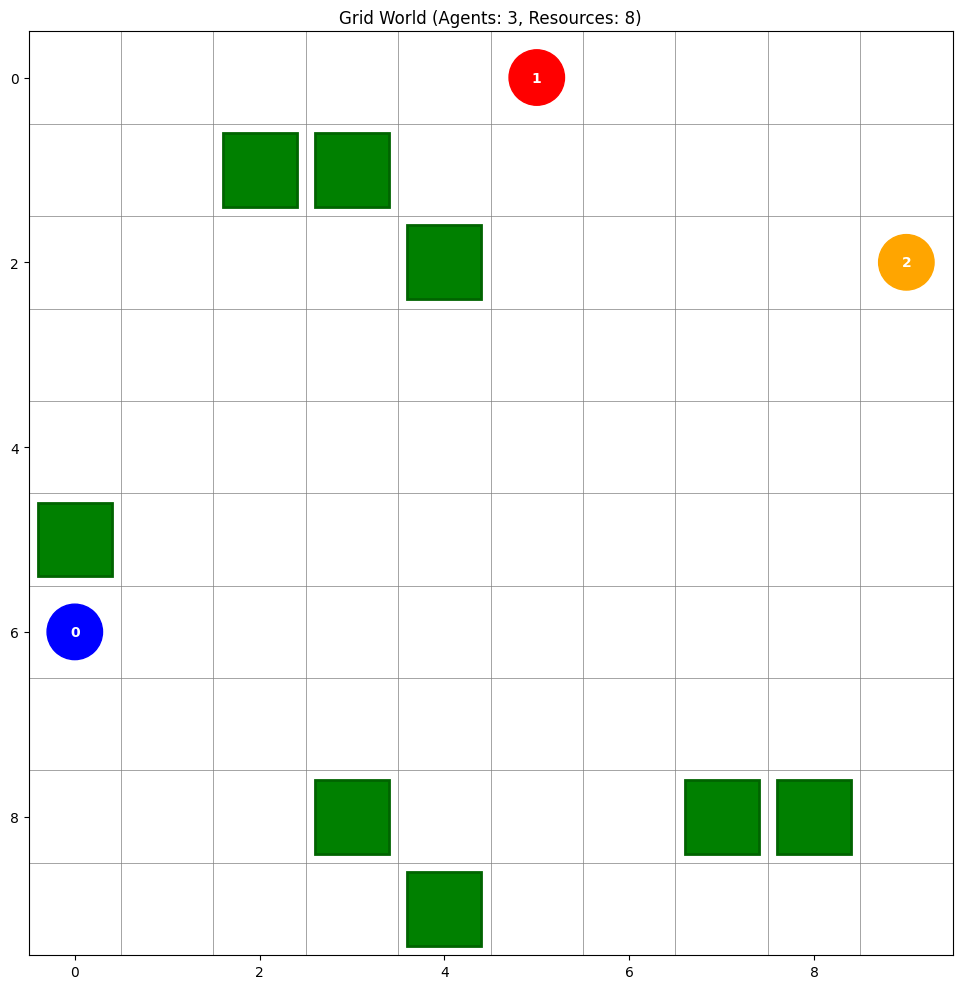

In [6]:
# Create multi-agent environment
env_multi = EmpathicGridEnv(
    grid_size=10,
    num_agents=3,
    num_resources=8,
    vision_radius=2,
    exploit_reward=1.0,
    empathic_penalty=-2.0
)

# Create agents
agents_multi = []
for i in range(3):
    agent = Agent(agent_id=i, memory_size=10, beta=0.5, threshold=0.5)
    agents_multi.append(agent)
env_multi.agents = agents_multi

# Reset and visualize
obs_multi, _ = env_multi.reset(seed=123)
visualize_grid(env_multi)


In [7]:
# Run a few steps and track consumption / empathic penalties
print("Running multi-agent simulation...\n")

for step in range(10):
    # Random actions for all agents
    actions = [np.random.randint(0, 4) for _ in range(3)]
    next_obs, rewards, done, truncated, info = env_multi.step(actions)

    print(f"Step {step + 1}:")
    for i in range(3):
        sat = agents_multi[i].get_satisfaction()
        pos = env_multi.agent_positions[i]
        reward = rewards[i]

        consumed = info.get('consumed', [False] * 3)[i]
        bonus = info.get('consumption_bonus', [0.0] * 3)[i]
        empathic_penalty_event = info.get('empathic_penalty_events', [False] * 3)[i]

        tags = []
        if consumed:
            tags.append("CONSUMED")
        if empathic_penalty_event:
            tags.append("EMPATHIC_PENALTY")
        tag_str = (" [" + ", ".join(tags) + "]") if tags else ""

        print(
            f"  Agent {i}: pos={pos}, reward={reward:+.3f}, "
            f"bonus={bonus:+.3f}, satisfaction={sat:.3f}{tag_str}"
        )

    print(f"  Resources remaining: {info.get('resources_remaining', len(env_multi.resource_positions))}")
    print()

    obs_multi = next_obs
    if done:
        break


Running multi-agent simulation...

Step 1:
  Agent 0: pos=(np.int64(1), np.int64(6)), reward=-0.010, bonus=+0.000, satisfaction=0.000
  Agent 1: pos=(np.int64(5), np.int64(0)), reward=-0.010, bonus=+0.000, satisfaction=0.000
  Agent 2: pos=(np.int64(9), np.int64(1)), reward=-0.010, bonus=+0.000, satisfaction=0.000
  Resources remaining: 8

Step 2:
  Agent 0: pos=(np.int64(0), np.int64(6)), reward=-0.010, bonus=+0.000, satisfaction=0.000
  Agent 1: pos=(np.int64(5), np.int64(1)), reward=-0.010, bonus=+0.000, satisfaction=0.000
  Agent 2: pos=(np.int64(8), np.int64(1)), reward=-0.010, bonus=+0.000, satisfaction=0.000
  Resources remaining: 8

Step 3:
  Agent 0: pos=(np.int64(0), np.int64(6)), reward=-0.010, bonus=+0.000, satisfaction=0.000
  Agent 1: pos=(np.int64(4), np.int64(1)), reward=-0.010, bonus=+0.000, satisfaction=0.000
  Agent 2: pos=(np.int64(7), np.int64(1)), reward=-0.010, bonus=+0.000, satisfaction=0.000
  Resources remaining: 8

Step 4:
  Agent 0: pos=(np.int64(1), np.int6

## Test 6: Test Satisfaction and Emotion Calculation

Verify that satisfaction and emotion are calculated correctly based on meal history.


In [8]:
# Create test agent
test_agent = Agent(agent_id=0, memory_size=10, beta=0.5, threshold=0.5)

print("Testing satisfaction and emotion calculation:\n")

# Simulate meal history
test_patterns = [
    ([0] * 10, "No meals"),
    ([1] * 10, "All meals"),
    ([1, 0, 1, 0, 1, 0, 1, 0, 1, 0], "Alternating"),
    ([0] * 5 + [1] * 5, "Recent meals"),
    ([1] * 5 + [0] * 5, "Old meals")
]

for pattern, description in test_patterns:
    test_agent.meal_history = deque(pattern, maxlen=10)
    sat = test_agent.get_satisfaction()
    emo = test_agent.get_emotion()
    rate = test_agent._consumption_rate()
    
    print(f"{description}:")
    print(f"  Pattern: {pattern}")
    print(f"  Consumption rate: {rate:.3f}")
    print(f"  Satisfaction: {sat:.3f}")
    print(f"  Emotion: {emo:.3f}")
    print()


Testing satisfaction and emotion calculation:

No meals:
  Pattern: [0, 0, 0, 0, 0, 0, 0, 0, 0, 0]
  Consumption rate: 0.000
  Satisfaction: 0.000
  Emotion: -1.000

All meals:
  Pattern: [1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
  Consumption rate: 1.000
  Satisfaction: 1.000
  Emotion: 1.000

Alternating:
  Pattern: [1, 0, 1, 0, 1, 0, 1, 0, 1, 0]
  Consumption rate: 0.500
  Satisfaction: 0.250
  Emotion: 0.000

Recent meals:
  Pattern: [0, 0, 0, 0, 0, 1, 1, 1, 1, 1]
  Consumption rate: 0.500
  Satisfaction: 0.750
  Emotion: 0.000

Old meals:
  Pattern: [1, 1, 1, 1, 1, 0, 0, 0, 0, 0]
  Consumption rate: 0.500
  Satisfaction: 0.250
  Emotion: 0.000



## Test 7: Test DQN Agent Action Selection

Test that DQN agent can select actions and learn.


In [9]:
# Create environment and DQN agent
env_dqn = EmpathicGridEnv(
    grid_size=8,
    num_agents=1,
    num_resources=5,
    vision_radius=2
)

dqn_agent = DQNAgent(
    agent_id=0,
    state_size=env_dqn.observation_space.shape,
    action_size=env_dqn.action_space.n,
    epsilon=1.0,  # Full exploration
    epsilon_min=0.1
)

env_dqn.agents = [dqn_agent.agent]

# Run a few steps
obs, _ = env_dqn.reset(seed=42)
dqn_agent.reset(observation=obs[0])

print("Testing DQN agent action selection:\n")

for step in range(10):
    # Select action
    action = dqn_agent.select_action(obs[0], training=True)
    action_names = ['Up', 'Down', 'Left', 'Right']
    
    # Step environment
    actions = [action]
    next_obs, rewards, done, truncated, info = env_dqn.step(actions)
    
    # Update agent
    dqn_agent.step(next_obs[0], rewards[0], done)
    
    print(f"Step {step + 1}: {action_names[action]}, reward={rewards[0]:+.3f}, "
          f"epsilon={dqn_agent.epsilon:.3f}, pos={env_dqn.agent_positions[0]}")
    
    obs = next_obs
    if done:
        break

print(f"\nReplay buffer size: {len(dqn_agent.memory)}")


Agent 0 using device: cuda
  GPU: NVIDIA GeForce RTX 4050 Laptop GPU


Testing DQN agent action selection:

Step 1: Up, reward=+0.990, epsilon=0.995, pos=(np.int64(0), np.int64(5))
Step 2: Right, reward=-0.010, epsilon=0.990, pos=(np.int64(1), np.int64(5))
Step 3: Down, reward=-0.010, epsilon=0.985, pos=(np.int64(1), np.int64(6))
Step 4: Right, reward=-0.010, epsilon=0.980, pos=(np.int64(2), np.int64(6))
Step 5: Left, reward=-0.010, epsilon=0.975, pos=(np.int64(1), np.int64(6))
Step 6: Up, reward=-0.010, epsilon=0.970, pos=(np.int64(1), np.int64(5))
Step 7: Down, reward=-0.010, epsilon=0.966, pos=(np.int64(1), np.int64(6))
Step 8: Right, reward=-0.010, epsilon=0.961, pos=(np.int64(2), np.int64(6))
Step 9: Left, reward=-0.010, epsilon=0.956, pos=(np.int64(1), np.int64(6))
Step 10: Right, reward=-0.010, epsilon=0.951, pos=(np.int64(2), np.int64(6))

Replay buffer size: 9


## Test 8: Visualize Observation Changes Over Steps

See how the agent's observation changes as it moves around.


Initial observation terrain (center 3x3):
[[-1.  1.  0.]
 [-1.  2.  0.]
 [-1.  0.  0.]]

Agent position: (np.int64(0), np.int64(7))

After action 1 (Down):
New position: (np.int64(0), np.int64(8))
New observation terrain (center 3x3):
[[-1.  0.  0.]
 [-1.  2.  0.]
 [-1.  0.  0.]]

After action 2 (Down):
New position: (np.int64(0), np.int64(9))
New observation terrain (center 3x3):
[[-1.  0.  0.]
 [-1.  2.  0.]
 [-1. -1. -1.]]

After action 3 (Left):
New position: (np.int64(0), np.int64(9))
New observation terrain (center 3x3):
[[-1.  0.  0.]
 [-1.  2.  0.]
 [-1. -1. -1.]]

After action 4 (Left):
New position: (np.int64(0), np.int64(9))
New observation terrain (center 3x3):
[[-1.  0.  0.]
 [-1.  2.  0.]
 [-1. -1. -1.]]


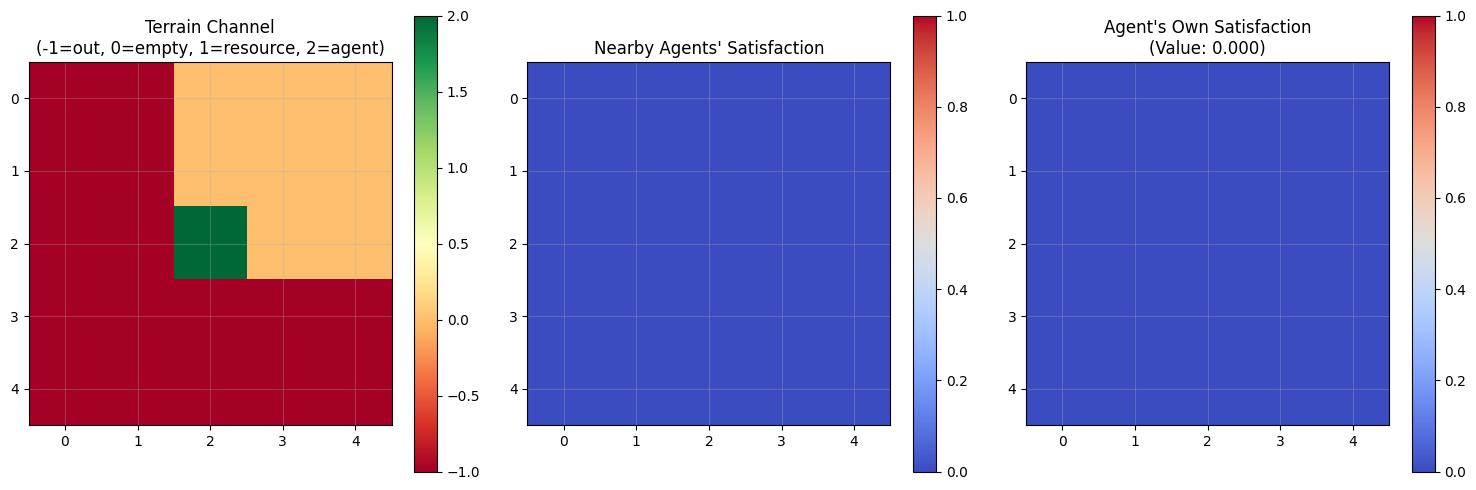


Center cell (agent position):
  Terrain value: 2.0
  Nearby satisfaction: 0.000
  Own satisfaction: 0.000


In [10]:
# Reset environment
obs, _ = env.reset(seed=42)
agent.reset()

print("Initial observation terrain (center 3x3):")
center_start = env.vision_radius - 1
center_end = env.vision_radius + 2
print(obs[0][center_start:center_end, center_start:center_end, 0])
print(f"\nAgent position: {env.agent_positions[0]}")

# Move agent and show new observation
actions_seq = [1, 1, 2, 2]  # Down, Down, Left, Left
for i, action in enumerate(actions_seq):
    next_obs, rewards, done, truncated, info = env.step([action])
    
    print(f"\nAfter action {i+1} ({['Up', 'Down', 'Left', 'Right'][action]}):")
    print(f"New position: {env.agent_positions[0]}")
    print("New observation terrain (center 3x3):")
    print(next_obs[0][center_start:center_end, center_start:center_end, 0])
    
    obs = next_obs

# Visualize final observation
visualize_observation(env, 0, obs[0])


## Test 9: Test Empathic Penalty Logic

Verify that empathic penalty is applied correctly when agent is more satisfied than neighbors.


In [11]:
# Create two agents with different satisfaction levels
env_empathy = EmpathicGridEnv(
    grid_size=8,
    num_agents=2,
    num_resources=3,
    vision_radius=2,
    exploit_reward=1.0,
    empathic_penalty=-2.0
)

agent1 = Agent(agent_id=0, memory_size=10)
agent2 = Agent(agent_id=1, memory_size=10)

# Make agent1 highly satisfied (many recent meals)
agent1.meal_history = deque([1] * 10, maxlen=10)
# Make agent2 less satisfied (few meals)
agent2.meal_history = deque([0] * 8 + [1] * 2, maxlen=10)

env_empathy.agents = [agent1, agent2]

print("Agent satisfaction levels:")
print(f"Agent 0: {agent1.get_satisfaction():.3f}")
print(f"Agent 1: {agent2.get_satisfaction():.3f}")
print()

# Place agents near each other with a resource, and force Agent 0 to *stay* on it.
# (There is no explicit "stay" action, so we use an invalid move at the boundary.)
env_empathy.agent_positions = [(0, 0), (0, 1)]
env_empathy.resource_positions = [(0, 0)]  # Agent 0 starts on resource

# Agent 0 (highly satisfied) attempts to move LEFT at x=0 (invalid) => stays on resource and consumes.
# Agent 1 is nearby and less satisfied => Agent 0 should get an empathic penalty event.
actions = [2, 2]  # left
next_obs, rewards, done, truncated, info = env_empathy.step(actions)

print("After step:")
print(f"Agent 0 reward: {rewards[0]:+.3f} (bonus={info.get('consumption_bonus',[0.0, 0.0])[0]:+.3f})")
print(f"Agent 1 reward: {rewards[1]:+.3f} (bonus={info.get('consumption_bonus',[0.0, 0.0])[1]:+.3f})")
print(f"Consumed flags: {info.get('consumed')}")
print(f"Empathic penalty events: {info.get('empathic_penalty_events')}")
print(
    "Expected: Agent 0 should have consumed, and usually triggers an empathic penalty event "
    "since it's more satisfied than the nearby Agent 1"
)


Agent satisfaction levels:
Agent 0: 1.000
Agent 1: 0.600

After step:
Agent 0 reward: -0.210 (bonus=-0.200)
Agent 1 reward: -0.010 (bonus=+0.000)
Consumed flags: [True, False]
Empathic penalty events: [True, False]
Expected: Agent 0 should have consumed, and usually triggers an empathic penalty event since it's more satisfied than the nearby Agent 1


## Test 10: Resource Consumption Test

Verify that resources are always consumed when agent steps on them.


In [12]:
# Test automatic resource consumption
env_consume = EmpathicGridEnv(
    grid_size=5,
    num_agents=1,
    num_resources=3,
    vision_radius=2
)

test_agent_consume = Agent(agent_id=0)
env_consume.agents = [test_agent_consume]

# Place agent next to a resource
env_consume.agent_positions = [(2, 2)]
env_consume.resource_positions = [(2, 1)]  # Resource above agent

initial_resources = len(env_consume.resource_positions)
print(f"Initial resources: {initial_resources}")
print(f"Resource position: {env_consume.resource_positions}")
print(f"Agent position: {env_consume.agent_positions[0]}")
print()

# Move agent onto resource (action 0 = up)
actions = [0]
old_resource_pos = env_consume.resource_positions[0]
next_obs, rewards, done, truncated, info = env_consume.step(actions)

final_resources = len(env_consume.resource_positions)
consumed_flag = info.get('consumed', [False])[0]

print("After moving onto resource:")
print(f"Final resources: {final_resources} (typically unchanged due to respawn)")
print(f"Consumed flag: {consumed_flag}")
print(f"Old resource still present: {old_resource_pos in env_consume.resource_positions}")
print(f"Reward: {rewards[0]:+.3f} (bonus={info.get('consumption_bonus',[0.0])[0]:+.3f})")
print(f"Agent meal history: {list(test_agent_consume.meal_history)[-5:]}")  # Last 5 entries


Initial resources: 1
Resource position: [(2, 1)]
Agent position: (2, 2)

After moving onto resource:
Final resources: 1 (typically unchanged due to respawn)
Consumed flag: True
Old resource still present: False
Reward: +0.990 (bonus=+1.000)
Agent meal history: [0, 0, 0, 0, 1]


## Additional Test Suggestions

Here are some additional tests you might want to add:

1. **Vision Radius Variations**: Test different vision radii (1, 2, 3) and see how it affects agent observations
2. **Beta Parameter Test**: Test how different beta values affect satisfaction calculation (weight of recent vs history)
3. **Threshold Parameter Test**: Test how different threshold values affect emotion calculation
4. **Collision Handling**: Test that agents cannot occupy the same cell
5. **Episode Termination**: Test that episodes terminate correctly when max_steps reached or resources depleted
6. **Reward Scaling**: Test different reward/penalty values and their impact on learning
7. **Multi-Episode Training**: Run multiple episodes with DQN agent and track learning progress
8. **Observation Consistency**: Verify that observations are consistent with actual grid state
9. **Resource Spawning**: Test that resources spawn correctly after consumption
10. **Edge Cases**: Test boundary conditions (agents at grid edges, vision at boundaries)


## Test 11: Compare Learning with and without Empathic Penalties

Compare learning curves for a single agent in two scenarios:
- Scenario 1: Normal learning (no empathic penalties)
- Scenario 2: Always penalized when consuming (simulating nearby unsatisfied agent)


In [13]:
# Create custom environment class that always applies empathic penalty
class AlwaysPenaltyEnv(EmpathicGridEnv):
    """Environment that always applies empathic penalty when consuming resources."""

    def step(self, actions):
        """Override step to always apply penalty when consuming."""
        self.steps_taken += 1
        rewards = [0.0] * self.num_agents
        consumed_flags = [False] * self.num_agents
        consumption_bonus = [0.0] * self.num_agents
        empathic_penalty_events = [False] * self.num_agents

        # Process movements and update positions
        new_positions = list(self.agent_positions)
        occupied_targets = set()

        for i, action in enumerate(actions):
            x, y = self.agent_positions[i]
            nx, ny = x, y  # default (stay in place)

            if action == 0 and y > 0:  # up
                nx, ny = x, y - 1
            elif action == 1 and y < self.grid_size - 1:  # down
                nx, ny = x, y + 1
            elif action == 2 and x > 0:  # left
                nx, ny = x - 1, y
            elif action == 3 and x < self.grid_size - 1:  # right
                nx, ny = x + 1, y

            # Prevent collisions
            if (nx, ny) in self.agent_positions and (nx, ny) != (x, y):
                nx, ny = x, y
            if (nx, ny) in occupied_targets:
                nx, ny = x, y
            occupied_targets.add((nx, ny))
            new_positions[i] = (nx, ny)

        self.agent_positions = new_positions

        # Process resource consumption with ALWAYS penalty
        for i in range(self.num_agents):
            x, y = self.agent_positions[i]
            reward = self.step_cost

            # Check if agent moved onto a resource
            if (x, y) in self.resource_positions:
                consumed_flags[i] = True

                # ALWAYS apply empathic penalty (simulating nearby unsatisfied agent)
                bonus = float(self.empathic_penalty)
                reward += bonus
                consumption_bonus[i] = bonus
                empathic_penalty_events[i] = bonus < 0.0

                success = True  # Resource is still consumed

                # Always remove resource and spawn new one (100% respawn rate)
                self.resource_positions.remove((x, y))
                empty_spots = [
                    (a, b) for a in range(self.grid_size) for b in range(self.grid_size)
                    if (a, b) not in self.resource_positions
                    and (a, b) not in self.agent_positions
                ]
                if empty_spots:
                    new_res = empty_spots[self.np_random.integers(0, len(empty_spots))]
                    self.resource_positions.append(new_res)

                self.agents[i].record_meal(success, 1.0)
            else:
                self.agents[i].record_meal(False, 0.0)

            rewards[i] = round(reward, 3)

        done = (self.steps_taken >= self.max_steps) or (len(self.resource_positions) == 0)
        observations = [self._get_obs(agent_idx) for agent_idx in range(self.num_agents)]
        info = {
            'steps': self.steps_taken,
            'resources_remaining': len(self.resource_positions),
            'satisfactions': [agent.get_satisfaction() for agent in self.agents],
            'consumed': consumed_flags,
            'consumption_bonus': consumption_bonus,
            'empathic_penalty_events': empathic_penalty_events,
        }
        return observations, rewards, done, False, info


print("Custom environments created successfully!")


Custom environments created successfully!


In [14]:
# Training function

def train_agent(env, num_episodes=100, max_steps_per_episode=50, seed=42):
    """Train a DQN agent and return episode rewards."""
    np.random.seed(seed)

    # Create DQN agent
    dqn_agent = DQNAgent(
        agent_id=0,
        state_size=env.observation_space.shape,
        action_size=env.action_space.n,
        learning_rate=0.001,
        gamma=0.99,
        epsilon=1.0,
        epsilon_decay=0.995,
        epsilon_min=0.1,
        batch_size=16,
        hidden_size=64,
        update_target_every=20,
    )

    # Link agent to environment (single-agent case)
    env.agents = [dqn_agent.agent]

    episode_rewards = []
    episode_steps = []
    episode_consumptions = []

    for episode in range(num_episodes):
        obs, _ = env.reset(seed=seed + episode)
        dqn_agent.reset(observation=obs[0])

        episode_reward = 0.0
        episode_consumed = 0

        for step in range(max_steps_per_episode):
            # Select action (with optional action masking)
            valid_actions = env.get_valid_actions(0) if hasattr(env, 'get_valid_actions') else None
            action = dqn_agent.select_action(obs[0], training=True, valid_actions=valid_actions)

            # Step environment
            next_obs, rewards, done, truncated, info = env.step([action])

            # Update agent (with optional action masking for next step)
            valid_actions_next = env.get_valid_actions(0) if hasattr(env, 'get_valid_actions') else None
            dqn_agent.step(
                next_state=next_obs[0],
                reward=rewards[0],
                done=done,
                valid_actions=valid_actions_next,
            )

            episode_reward += float(rewards[0])

            # Robust consumption signal (env always respawns, so counts may not change)
            if info.get('consumed', [False])[0]:
                episode_consumed += 1

            obs = next_obs
            if done:
                break

        episode_rewards.append(episode_reward)
        episode_steps.append(step + 1)
        episode_consumptions.append(episode_consumed)

    return episode_rewards, episode_steps, episode_consumptions


print("Training function created!")


Training function created!


Environments created:
Grid size: 3x3 (agent can see everything)
Vision radius: 2 (5x5 observation window)
Scenario 1: Normal rewards
Scenario 2: Always penalized when consuming

Normal environment initial state:


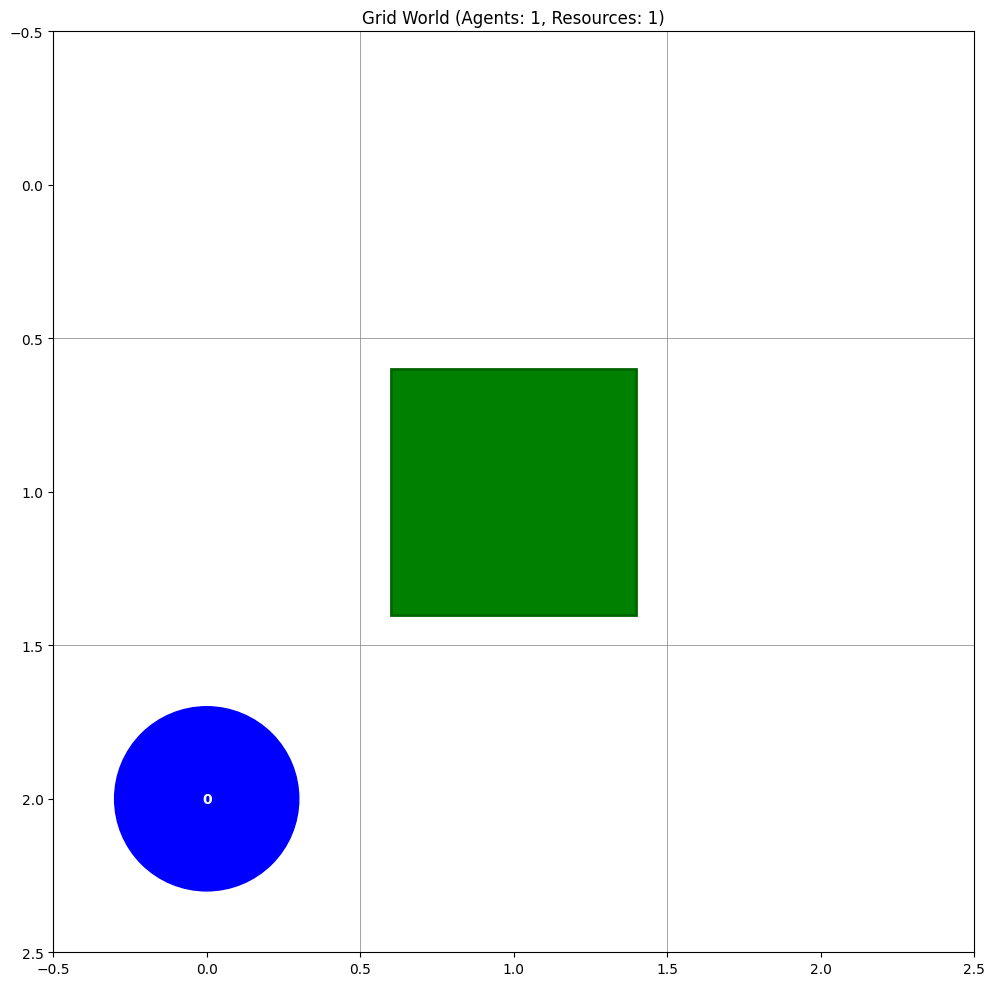

In [15]:
# Create two environments
# Scenario 1: Normal learning (no penalty)
env_normal = EmpathicGridEnv(
    grid_size=3,
    num_agents=1,
    num_resources=1,
    vision_radius=2,  # Can see whole grid (3x3 grid, radius 2 = 5x5 view)
    exploit_reward=1.0,
    empathic_penalty=-2.0,  # Not used in normal scenario
    step_cost=-0.01,
    max_steps=50
)

# Scenario 2: Always penalized (simulating nearby unsatisfied agent)
env_penalty = AlwaysPenaltyEnv(
    grid_size=3,
    num_agents=1,
    num_resources=1,
    vision_radius=2,
    exploit_reward=1.0,
    empathic_penalty=-2.0,  # Always applied
    step_cost=-0.01,
    max_steps=50
)

print("Environments created:")
print(f"Grid size: 3x3 (agent can see everything)")
print(f"Vision radius: 2 (5x5 observation window)")
print(f"Scenario 1: Normal rewards")
print(f"Scenario 2: Always penalized when consuming")
print()

# Visualize initial state of normal environment
agent_temp = Agent(agent_id=0)
env_normal.agents = [agent_temp]
obs_normal, _ = env_normal.reset(seed=42)
print("Normal environment initial state:")
visualize_grid(env_normal)


In [16]:
# Train both agents
print("Training Scenario 1 (Normal Learning)...")
rewards_normal, steps_normal, consumptions_normal = train_agent(
    env_normal, 
    num_episodes=200, 
    max_steps_per_episode=50,
    seed=42
)

print("Training Scenario 2 (Always Penalized)...")
rewards_penalty, steps_penalty, consumptions_penalty = train_agent(
    env_penalty,
    num_episodes=200,
    max_steps_per_episode=50,
    seed=42
)

print("Training completed!")


Training Scenario 1 (Normal Learning)...
Agent 0 using device: cuda
  GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Training Scenario 2 (Always Penalized)...
Agent 0 using device: cuda
  GPU: NVIDIA GeForce RTX 4050 Laptop GPU
Training completed!


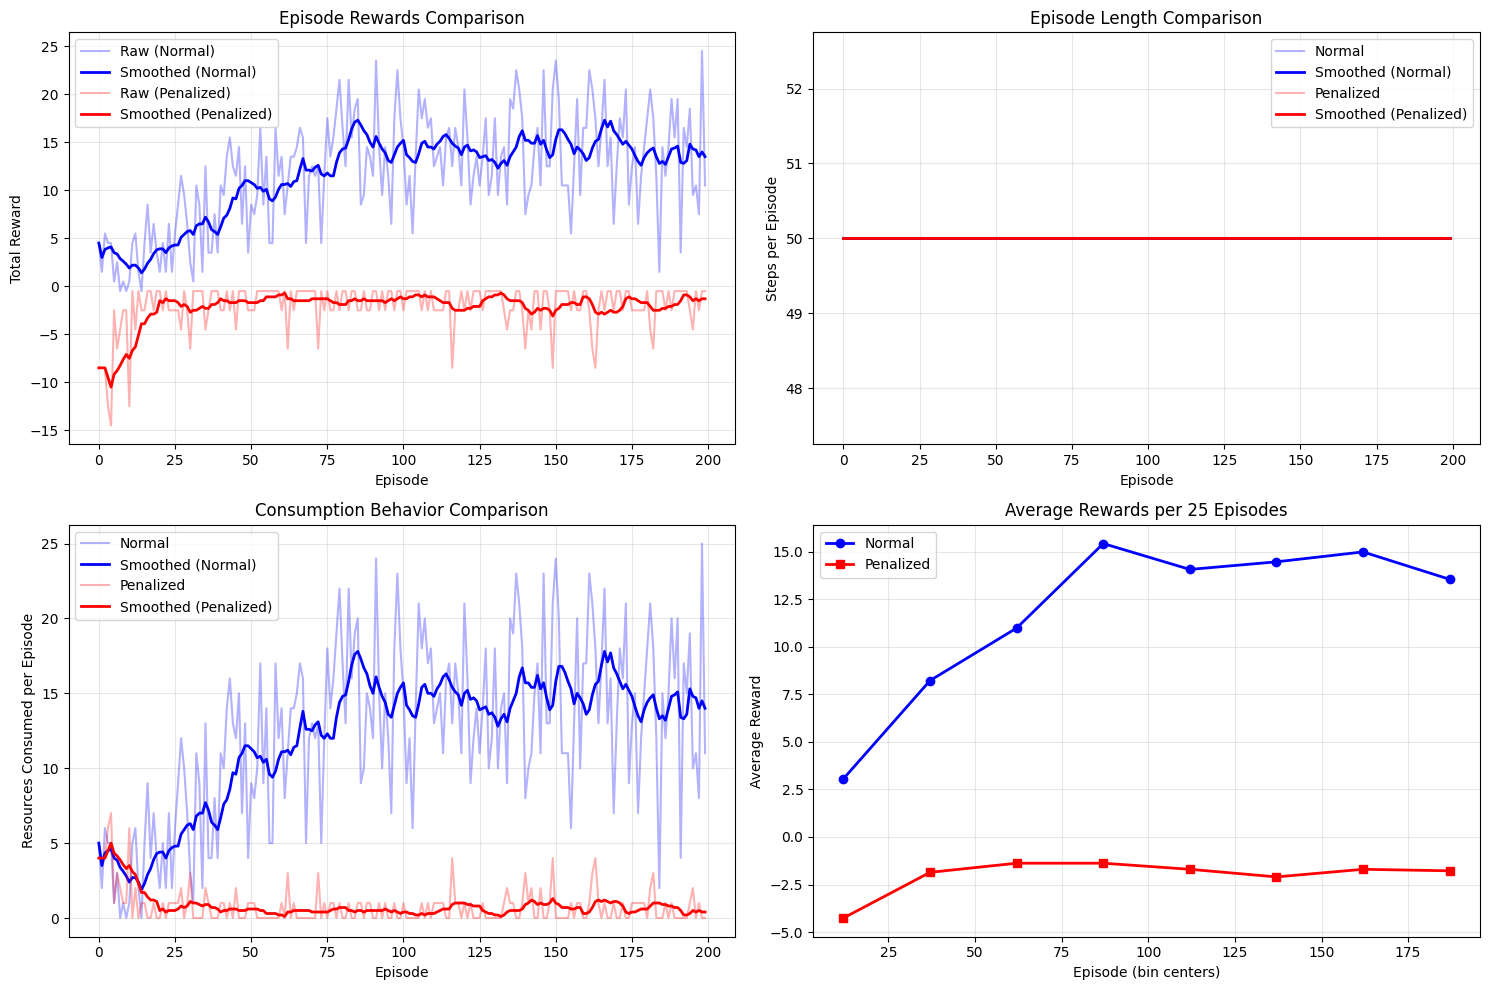


LEARNING COMPARISON SUMMARY

Scenario 1 (Normal Learning):
  Average reward (first 25 episodes): 3.060
  Average reward (last 25 episodes): 13.540
  Average consumptions per episode: 12.34
  Final episode reward: 10.500

Scenario 2 (Always Penalized):
  Average reward (first 25 episodes): -4.260
  Average reward (last 25 episodes): -1.780
  Average consumptions per episode: 0.76
  Final episode reward: -0.500

Key Insights:
  - Normal agent learns to consume resources (reward improvement: 10.480)
  - Penalized agent learns to avoid consuming (reward improvement: 2.480)
  - Normal agent consumes 16.2x more per episode on average


In [17]:
# Plot comparison of learning curves
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Smooth rewards using moving average
def smooth_curve(data, window=10):
    """Apply moving average smoothing."""
    smoothed = []
    for i in range(len(data)):
        start = max(0, i - window + 1)
        smoothed.append(np.mean(data[start:i+1]))
    return smoothed

# Plot 1: Episode Rewards
axes[0, 0].plot(rewards_normal, alpha=0.3, color='blue', label='Raw (Normal)')
axes[0, 0].plot(smooth_curve(rewards_normal), color='blue', linewidth=2, label='Smoothed (Normal)')
axes[0, 0].plot(rewards_penalty, alpha=0.3, color='red', label='Raw (Penalized)')
axes[0, 0].plot(smooth_curve(rewards_penalty), color='red', linewidth=2, label='Smoothed (Penalized)')
axes[0, 0].set_xlabel('Episode')
axes[0, 0].set_ylabel('Total Reward')
axes[0, 0].set_title('Episode Rewards Comparison')
axes[0, 0].legend()
axes[0, 0].grid(True, alpha=0.3)

# Plot 2: Episode Steps (how long episodes last)
axes[0, 1].plot(steps_normal, alpha=0.3, color='blue', label='Normal')
axes[0, 1].plot(smooth_curve(steps_normal), color='blue', linewidth=2, label='Smoothed (Normal)')
axes[0, 1].plot(steps_penalty, alpha=0.3, color='red', label='Penalized')
axes[0, 1].plot(smooth_curve(steps_penalty), color='red', linewidth=2, label='Smoothed (Penalized)')
axes[0, 1].set_xlabel('Episode')
axes[0, 1].set_ylabel('Steps per Episode')
axes[0, 1].set_title('Episode Length Comparison')
axes[0, 1].legend()
axes[0, 1].grid(True, alpha=0.3)

# Plot 3: Resource Consumptions per Episode
axes[1, 0].plot(consumptions_normal, alpha=0.3, color='blue', label='Normal')
axes[1, 0].plot(smooth_curve(consumptions_normal), color='blue', linewidth=2, label='Smoothed (Normal)')
axes[1, 0].plot(consumptions_penalty, alpha=0.3, color='red', label='Penalized')
axes[1, 0].plot(smooth_curve(consumptions_penalty), color='red', linewidth=2, label='Smoothed (Penalized)')
axes[1, 0].set_xlabel('Episode')
axes[1, 0].set_ylabel('Resources Consumed per Episode')
axes[1, 0].set_title('Consumption Behavior Comparison')
axes[1, 0].legend()
axes[1, 0].grid(True, alpha=0.3)

# Plot 4: Average rewards in bins
bin_size = 25
num_bins = len(rewards_normal) // bin_size
normal_binned = [np.mean(rewards_normal[i*bin_size:(i+1)*bin_size]) for i in range(num_bins)]
penalty_binned = [np.mean(rewards_penalty[i*bin_size:(i+1)*bin_size]) for i in range(num_bins)]

x_bins = [i*bin_size + bin_size//2 for i in range(num_bins)]
axes[1, 1].plot(x_bins, normal_binned, 'o-', color='blue', label='Normal', linewidth=2, markersize=6)
axes[1, 1].plot(x_bins, penalty_binned, 's-', color='red', label='Penalized', linewidth=2, markersize=6)
axes[1, 1].set_xlabel('Episode (bin centers)')
axes[1, 1].set_ylabel('Average Reward')
axes[1, 1].set_title(f'Average Rewards per {bin_size} Episodes')
axes[1, 1].legend()
axes[1, 1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Print summary statistics
print("\n" + "="*60)
print("LEARNING COMPARISON SUMMARY")
print("="*60)
print(f"\nScenario 1 (Normal Learning):")
print(f"  Average reward (first 25 episodes): {np.mean(rewards_normal[:25]):.3f}")
print(f"  Average reward (last 25 episodes): {np.mean(rewards_normal[-25:]):.3f}")
print(f"  Average consumptions per episode: {np.mean(consumptions_normal):.2f}")
print(f"  Final episode reward: {rewards_normal[-1]:.3f}")

print(f"\nScenario 2 (Always Penalized):")
print(f"  Average reward (first 25 episodes): {np.mean(rewards_penalty[:25]):.3f}")
print(f"  Average reward (last 25 episodes): {np.mean(rewards_penalty[-25:]):.3f}")
print(f"  Average consumptions per episode: {np.mean(consumptions_penalty):.2f}")
print(f"  Final episode reward: {rewards_penalty[-1]:.3f}")

print(f"\nKey Insights:")
improvement_normal = np.mean(rewards_normal[-25:]) - np.mean(rewards_normal[:25])
improvement_penalty = np.mean(rewards_penalty[-25:]) - np.mean(rewards_penalty[:25])
consumption_ratio = np.mean(consumptions_normal) / max(np.mean(consumptions_penalty), 0.01)
print(f"  - Normal agent learns to consume resources (reward improvement: {improvement_normal:.3f})")
print(f"  - Penalized agent learns to avoid consuming (reward improvement: {improvement_penalty:.3f})")
print(f"  - Normal agent consumes {consumption_ratio:.1f}x more per episode on average")


## Analysis of Learning Comparison

### Expected Behavior:

1. **Normal Scenario**: 
   - Agent learns to find and consume resources
   - Rewards increase over time as agent learns navigation
   - Agent consumes resources regularly once it learns

2. **Penalized Scenario**:
   - Agent receives negative reward every time it consumes
   - Agent should learn to avoid consuming resources
   - Rewards may improve slightly as agent learns to navigate efficiently (avoiding resources)
   - Consumption rate should decrease over time

### Key Differences to Observe:

- **Reward trajectories**: Normal should increase, penalized should remain negative or decrease
- **Consumption behavior**: Normal agent should consume more over time, penalized agent should consume less
- **Episode length**: Both should improve navigation efficiency, but penalized agent may take longer to learn
